# 05 Where to bid - market opportunities

Point of view: a company that wants to start bidding in public tenders. A good market is
- big (a lot of money and many lots)
- with weak competition (few offers per lot)
- not dominated by one company (otherwise it is hard to win against the incumbent)
- with many different buyers (not dependent on one client)

Markets are CPV groups (first 3 digits of the code, e.g. 331 = medical equipment).

In [1]:
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

con = duckdb.connect("../data/tenders.duckdb", read_only=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)


def q(sql):
    return con.sql(sql).df()

In [2]:
segments = q('''
WITH groups AS (
    SELECT left(cpv, 3) AS cpv_group, name_en AS group_name
    FROM ref_cpv
    WHERE cpv LIKE '___00000'
),
lots AS (
    SELECT *, left(cpv, 3) AS cpv_group
    FROM fact_lot
    WHERE n_offers >= 1
),
winner_share AS (
    SELECT cpv_group, winner_key, sum(value_pln) AS won
    FROM lots
    WHERE winner_key IS NOT NULL AND value_pln IS NOT NULL
    GROUP BY ALL
),
concentration AS (
    SELECT cpv_group,
        max(won) / sum(won) AS top_winner_share,
        sum(power(won / total, 2)) AS hhi
    FROM (SELECT *, sum(won) OVER (PARTITION BY cpv_group) AS total FROM winner_share)
    GROUP BY 1
)
SELECT
    l.cpv_group,
    g.group_name,
    count(*) AS lots,
    sum(value_pln) / 1e6 AS value_mln,
    median(value_pln) / 1e3 AS median_lot_k,
    avg(least(n_offers, 20)) AS avg_offers,
    avg(single_offer::int) AS single_offer_share,
    count(DISTINCT buyer_key) AS buyers,
    count(DISTINCT winner_key) AS winners,
    median(price_to_estimate) AS median_price_to_estimate,
    c.top_winner_share,
    c.hhi
FROM lots l
JOIN groups g USING (cpv_group)
JOIN concentration c USING (cpv_group)
GROUP BY ALL
HAVING count(*) >= 200
''')
len(segments)

95

## Score

`avg_offers` is capped at 20 per lot so a few lots with 100+ offers don't dominate.
Each metric is turned into a percentile rank (0-1) so they can be added together:
value and number of buyers count as plus, offers per lot and top winner share as minus.

In [3]:
s = segments.copy()
s["score"] = (
    s["value_mln"].rank(pct=True)
    + s["buyers"].rank(pct=True)
    + (1 - s["avg_offers"].rank(pct=True))
    + (1 - s["top_winner_share"].rank(pct=True))
) / 4
cols = ["cpv_group", "group_name", "lots", "value_mln", "avg_offers", "single_offer_share",
        "buyers", "top_winner_share", "median_price_to_estimate", "score"]
top = s.sort_values("score", ascending=False)[cols].head(15)
top["group_name"] = top["group_name"].str.slice(0, 45)
top

,cpv_group,group_name,lots,value_mln,avg_offers,single_offer_share,buyers,top_winner_share,median_price_to_estimate,score
56,331,Medical equipments,39257,"30,443.47",1.52,0.74,775,0.04,1.00,0.96
68,905,Refuse and waste related services,5843,"24,941.82",1.86,0.56,2116,0.04,1.00,0.95
62,336,Pharmaceutical products,43781,"49,290.06",1.99,0.60,639,0.12,0.98,0.87
54,480,Software package and information systems,1429,"5,059.85",1.64,0.67,464,0.11,1.00,0.86
64,722,Software programming and consultancy services,1399,"7,794.20",1.61,0.73,497,0.13,1.00,0.84
78,341,Motor vehicles,3724,"16,456.11",1.88,0.58,1443,0.23,1.06,0.78
46,665,Insurance and pension services,1251,"2,290.72",2.09,0.33,518,0.12,0.81,0.76
44,502,"Repair, maintenance and associated services r",950,"8,332.20",1.70,0.60,241,0.18,1.00,0.76
67,661,Banking and investment services,999,"4,833.59",2.69,0.21,696,0.11,0.95,0.76
90,906,Cleaning and sanitation services in urban or,2615,"10,700.41",2.33,0.44,412,0.13,0.92,0.75


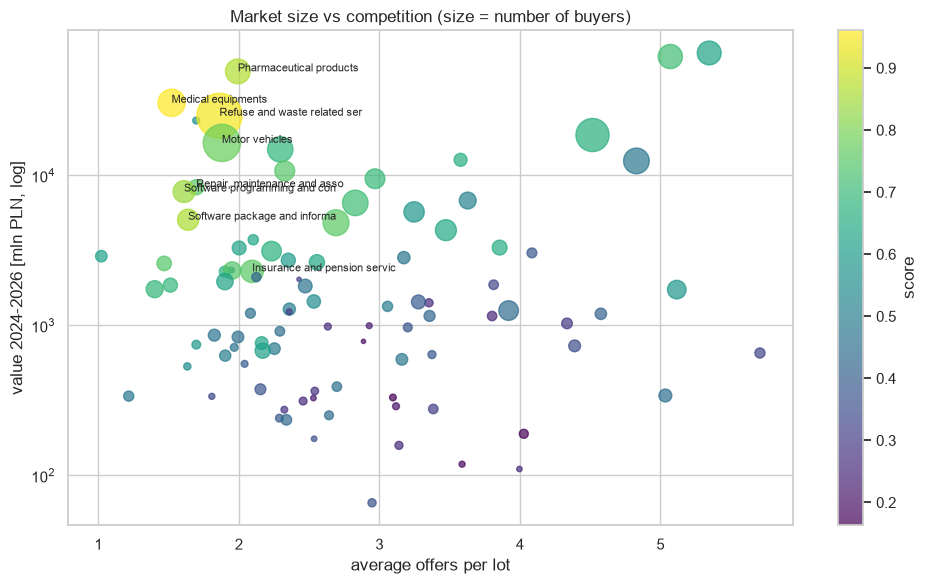

In [4]:
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(s["avg_offers"], s["value_mln"], s=s["buyers"] / 2, c=s["score"], cmap="viridis", alpha=0.7)
for _, r in s.sort_values("score", ascending=False).head(8).iterrows():
    ax.annotate(r["group_name"][:28], (r["avg_offers"], r["value_mln"]), fontsize=8)
ax.set(yscale="log", xlabel="average offers per lot", ylabel="value 2024-2026 [mln PLN, log]",
       title="Market size vs competition (size = number of buyers)")
plt.colorbar(sc, label="score")
plt.tight_layout()
plt.savefig("../images/opportunities.png", dpi=120)

The best markets are in the top-left corner: a lot of money and few competitors.

## Markets to avoid

High value but one company wins most of it - a newcomer would have to beat the incumbent.

In [5]:
dominated = s[s["value_mln"] > 500].sort_values("top_winner_share", ascending=False)
dominated[["cpv_group", "group_name", "value_mln", "top_winner_share", "avg_offers"]].head(8)

,cpv_group,group_name,value_mln,top_winner_share,avg_offers
3,805,Training services,"1,414.50",0.75,3.35
87,909,Cleaning and sanitation services,"12,478.31",0.66,4.83
9,347,Aircraft and spacecraft,995.04,0.66,2.93
40,244,Fertilisers and nitrogen compounds,782.60,0.64,2.89
65,421,Machinery for the production and use of mechan...,"2,096.94",0.62,2.12
88,150,"Food, beverages, tobacco and related products",982.32,0.60,2.63
18,380,"Laboratory, optical and precision equipments (...",860.49,0.55,1.83
80,907,Environmental services,"1,154.38",0.54,3.80


## Buyers that always pick the same company

For buyers with at least 10 lots in a market: what share of those lots was won by their most common
winner. A high share could mean a loyal supplier or tender conditions written for one company.

In [6]:
lock_in = q('''
WITH t AS (
    SELECT buyer_key, left(cpv, 3) AS cpv_group, winner_key, count(*) AS n
    FROM fact_lot
    WHERE winner_key IS NOT NULL
    GROUP BY ALL
),
b AS (
    SELECT buyer_key, cpv_group, sum(n) AS lots, max(n) / sum(n) AS top_winner_share
    FROM t
    GROUP BY ALL
    HAVING sum(n) >= 10
)
SELECT
    count(*) AS buyer_market_pairs,
    round(avg((top_winner_share >= 0.8)::int), 3) AS share_with_80pct_one_winner,
    round(median(top_winner_share), 3) AS median_top_winner_share
FROM b
''')
lock_in

,buyer_market_pairs,share_with_80pct_one_winner,median_top_winner_share
0,2701,0.05,0.25


## Summary

- best markets for a newcomer combine high value, many buyers and weak competition
- some big markets are dominated by one or two companies and are hard to enter
- buyers are usually not locked to one supplier: only ~5% of buyer-market pairs give 80%+ of lots
  to the same company, the median is 25%